# Etapa 0. Ingesta y buffer (cola FIFO)

**Proyecto EDA 2026-2, Grupo 1, escenario B (comercio electrónico).**
Responsable de las etapas 0, 1 y 2: Cristina.

## Función de la etapa en el pipeline

La etapa 0 es la puerta de entrada del pipeline. Recibe un flujo continuo de eventos de comercio electrónico y lo guarda temporalmente en un buffer FIFO. Después entrega esos eventos a la etapa 1 en micro-lotes. El buffer desacopla la velocidad del productor (el generador de eventos) de la velocidad del consumidor (el preprocesamiento). Cuando el consumidor es más lento, el buffer se llena y el productor espera. Este mecanismo se llama backpressure.

## Pasos del notebook

1. Configuración, importada de `src/config.py`.
2. Lectura de las reseñas como stream, desde un Parquet y dentro de una ventana reciente.
3. Carga del catálogo de productos (precio, categoría y título).
4. Generador sintético de eventos de comercio electrónico.
5. Implementación propia de la cola FIFO (buffer circular y lista enlazada).
6. Buffer con backpressure y formación de micro-lotes.
7. Ejecución de la etapa 0 y métricas observadas.
8. Experimentos de complejidad (tiempo y memoria) frente a `list.pop(0)` y `collections.deque`.
9. Salida de la etapa 0 para la etapa 1.

## Paso 1. Configuración

La categoría, las rutas de los datos, la semilla y el tamaño del experimento están en `src/config.py`, el único lugar del proyecto donde se escriben. Este notebook los importa.

- Los datos se generan con `notebooks/00-download-data.ipynb`. Ese notebook deja en `data/raw/` las reseñas de `Office_Products` ordenadas por `timestamp` y los metadatos de productos, ambos en Parquet.
- `SEED = 42` hace que el generador produzca siempre los mismos eventos.
- `MODO` elige el tamaño. En `"desarrollo"` se procesan 50 000 reseñas y en `"experimento"`, 2 500 000.
- `RAIZ` es la carpeta raíz del proyecto. Se busca subiendo desde la carpeta actual hasta encontrar la que contiene `notebooks/` y `data/`, para poder importar `src/` aunque el notebook se abra desde otra ubicación.
- Los resultados de los experimentos se guardan en `results/` y la salida de la etapa en `data/interim/<CATEGORIA>/`. Los archivos que dependen de los datos llevan la categoría en el nombre.

In [1]:
import gc
import inspect
import json
import platform
import statistics
import sys
import threading
import time
import tracemalloc
from collections import Counter, deque
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))       # para importar src/

from src import config

SEED = config.SEED
CATEGORIA = config.CATEGORIA
RUTA_RESENAS = config.RUTA_RESENAS
RUTA_META = config.RUTA_META
CARPETA_RESULTADOS = config.CARPETA_RESULTADOS
CARPETA_INTERIM = config.CARPETA_INTERIM
CARPETA_RESULTADOS.mkdir(exist_ok=True)
CARPETA_INTERIM.mkdir(parents=True, exist_ok=True)

assert RUTA_RESENAS.exists(), "Faltan las reseñas en Parquet. Ejecutar antes notebooks/00-download-data.ipynb"
assert RUTA_META.exists(), "Faltan los metadatos en Parquet. Ejecutar antes notebooks/00-download-data.ipynb"

# Plataforma (el enunciado pide reportarla junto con la semilla)
PLATAFORMA = {
    "sistema": platform.platform(),
    "procesador": platform.processor(),
    "nucleos": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "python": platform.python_version(),
    "semilla": SEED,
}
print(f"Categoría: {CATEGORIA}   modo: {config.MODO} ({config.n_resenas():,} reseñas)   "
      f"tardíos: {config.PORCENTAJE_TARDIOS:.0%}, hasta {config.RETRASO_MAX_TARDIOS_S} s")
PLATAFORMA

Categoría: Office_Products   modo: desarrollo (50,000 reseñas)   tardíos: 5%, hasta 120 s


{'sistema': 'Windows-10-10.0.26200-SP0',
 'procesador': 'Intel64 Family 6 Model 158 Stepping 10, GenuineIntel',
 'nucleos': 12,
 'ram_gb': 17.0,
 'python': '3.11.1',
 'semilla': 42}

## Paso 2. Las reseñas como stream

Las reseñas están en un Parquet de unos 12.8 millones de filas, ordenadas por `timestamp`. No se cargan completas. Se leen con `ParquetFile.iter_batches`, que entrega bloques de 10 000 filas y solo las columnas necesarias, y un **generador** de Python (`yield`) entrega las reseñas una a la vez. La memoria usada depende del tamaño del bloque y no del número de reseñas.

### Ventana reciente

El experimento usa las **últimas** 2 500 000 reseñas del archivo, que forman un bloque continuo al final de las reseñas ordenadas por tiempo. Son las más recientes, así que representan el comportamiento actual de la tienda, y al ser un bloque continuo conservan el orden temporal real del stream. El modo desarrollo usa las primeras 50 000 reseñas de esa misma ventana.

Un Parquet se divide en **grupos de filas** (*row groups*), y sus metadatos guardan cuántas filas tiene cada grupo. Con esos metadatos se calcula en qué grupo empieza la ventana sin leer ningún dato. Los grupos anteriores no se leen, y dentro del primer grupo se descartan las filas previas al inicio de la ventana.

### Por qué un stream y no una lista

- El disco y la RAM son recursos distintos. El archivo ocupa disco, pero procesarlo completo en una lista ocuparía RAM, que es más escasa.
- Un stream real no tiene fin, así que no es posible cargar todo y procesarlo después.
- La memoria del generador es O(1) respecto al número de reseñas, mientras que una lista ocupa O(n).
- Los resultados salen desde el primer registro, lo que reduce la latencia.

La lectura está implementada en `src/generator.py` (`describir_ventana` y `leer_resenas`).

In [2]:
from src.generator import describir_ventana, leer_resenas

# Qué filas y grupos de filas se leen, calculado solo con los metadatos del Parquet
ventanas = {
    "experimento": describir_ventana(n_ventana=config.N_RESENAS_EXPERIMENTO),
    "desarrollo": describir_ventana(n_ventana=config.N_RESENAS_EXPERIMENTO, limite=config.N_RESENAS_DESARROLLO),
}
display(pd.DataFrame({modo: {"filas del archivo": v["total_filas"], "inicio de la ventana": v["inicio"],
                             "fin de la ventana": v["fin"], "reseñas": v["filas"],
                             "grupos de filas del archivo": v["grupos_totales"],
                             "grupos que se leen": len(v["grupos_leidos"]),
                             "filas descartadas del primer grupo": v["filas_a_descartar"]}
                      for modo, v in ventanas.items()}))

# Ejemplo: las tres primeras reseñas de la ventana
for resena in leer_resenas(limite=3):
    print(resena)

,experimento,desarrollo
filas del archivo,12845712,12845712
inicio de la ventana,10345712,10345712
fin de la ventana,12845712,10395712
reseñas,2500000,50000
grupos de filas del archivo,65,65
grupos que se leen,14,1
filas descartadas del primer grupo,145712,145712


{'user_id': 'AFPC74SU4JGIGVUMFLBHOOARJSBQ', 'parent_asin': 'B087S2JRXY', 'rating': 5.0, 'verified_purchase': True, 'timestamp': 1635003458220}
{'user_id': 'AH7SOZ6AAMSP6PBOVSIDFOVMI36Q', 'parent_asin': 'B081DJ42JX', 'rating': 5.0, 'verified_purchase': True, 'timestamp': 1635003481526}
{'user_id': 'AGOLF5UC5PROCGWFT7C6QFGR4XFQ', 'parent_asin': 'B0BZYJPRL5', 'rating': 1.0, 'verified_purchase': True, 'timestamp': 1635003487223}


### Comprobación empírica: generador frente a lista

Se mide la memoria pico con `tracemalloc` al recorrer 100 000 reseñas de dos formas. La primera usa el generador y la segunda guarda todo en una lista antes de recorrerla. El número de reseñas leídas es el mismo en ambos casos.

In [3]:
def memoria_pico_mb(funcion):
    """Ejecuta funcion() y devuelve la memoria pico (MB) registrada por tracemalloc."""
    gc.collect()
    tracemalloc.start()
    funcion()
    _, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return pico / 1e6


N_PRUEBA = 100_000

def recorrer_con_generador():
    total = 0
    for _ in leer_resenas(limite=N_PRUEBA):
        total += 1
    return total

def recorrer_con_lista():
    todas = list(leer_resenas(limite=N_PRUEBA))   # todo queda en RAM
    total = 0
    for _ in todas:
        total += 1
    return total

pico_gen = memoria_pico_mb(recorrer_con_generador)
pico_lista = memoria_pico_mb(recorrer_con_lista)
print(f"Memoria pico con generador: {pico_gen:8.2f} MB")
print(f"Memoria pico con lista:     {pico_lista:8.2f} MB")
print(f"La lista usa {pico_lista / pico_gen:.0f} veces más memoria para {N_PRUEBA:,} reseñas.")

Memoria pico con generador:     4.28 MB
Memoria pico con lista:        40.53 MB
La lista usa 9 veces más memoria para 100,000 reseñas.


### Rendimiento al crecer el número de reseñas

La comprobación anterior usa un solo tamaño. Para ver cómo escala cada forma de lectura se repite con 1K, 10K, 50K, 100K y 200K reseñas y se miden tres cosas.

- **Memoria pico** con `tracemalloc`. Con la lista se espera O(n), porque guarda todas las reseñas; con el generador, O(1), porque guarda una sola a la vez.
- **Tiempo hasta el primer registro**, es decir, cuánto tarda el consumidor en tener el primer registro para procesar. Es la latencia de arranque del pipeline. La lista debe leer el archivo completo antes de entregar algo; el generador entrega el primero tras leer una línea.
- **Tiempo total** de recorrer todas las reseñas. Sirve para comprobar que el generador no paga su ahorro de memoria con más tiempo.

La memoria se mide en una ejecución aparte de los tiempos, porque `tracemalloc` hace más lento el código que observa. Los tiempos son el promedio de 5 repeticiones. Los resultados se guardan en `results/etapa0_stream_vs_lista_<CATEGORIA>.csv` y se reutilizan si el archivo existe; para medir de nuevo se cambia `REEJECUTAR_STREAM` a `True`.

n =   1,000 medido


n =  10,000 medido


n =  50,000 medido


n = 100,000 medido


n = 200,000 medido


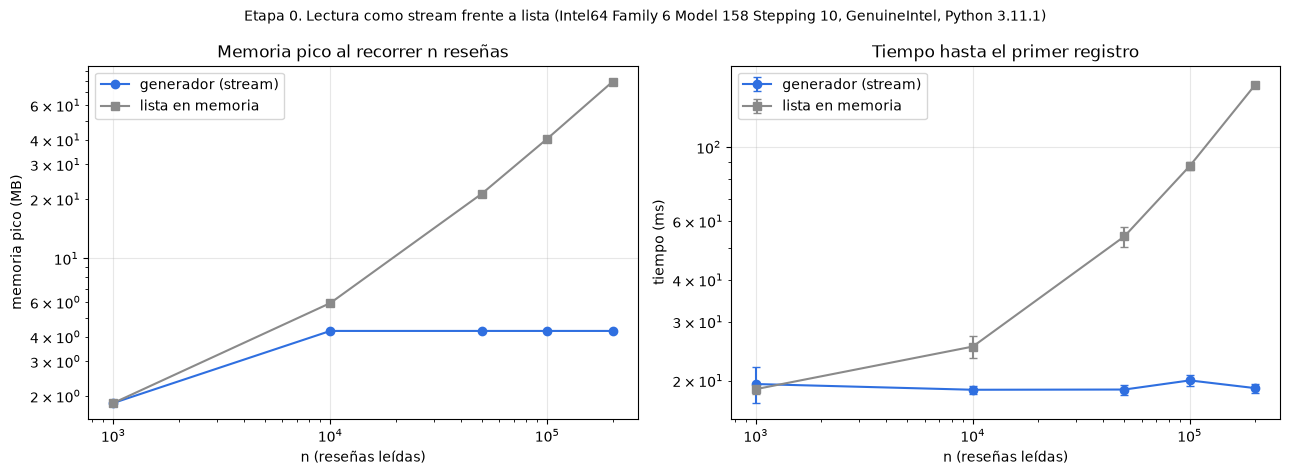

memoria_pico_mb         primer_registro_ms            total_s       
forma        generador   lista          generador    lista generador  lista
n                                                                          
1000             1.841   1.841             19.519   18.843     0.019  0.019
10000            4.277   5.926             18.764   25.271     0.025  0.025
50000            4.277  21.325             18.793   54.024     0.051  0.052
100000           4.277  40.534             20.014   87.749     0.083  0.088
200000           4.277  78.959             18.978  153.360     0.145  0.158

Con 200,000 reseñas:
  memoria pico:         lista 79.0 MB, generador 4.28 MB (18 veces menos)
  primer registro:      lista 153 ms, generador 18.978 ms
  recorrido completo:   lista 0.16 s, generador 0.15 s


In [4]:
REEJECUTAR_STREAM = False
TAMANOS_STREAM = [1_000, 10_000, 50_000, 100_000, 200_000]
REPETICIONES_STREAM = 5
ruta_stream = CARPETA_RESULTADOS / f"etapa0_stream_vs_lista_{CATEGORIA}.csv"


def primer_registro(forma, n):
    """Segundos hasta tener el primer registro disponible para procesar."""
    t0 = time.perf_counter()
    if forma == "generador":
        lector = leer_resenas(limite=n)
        next(lector)                       # basta leer una línea
        lector.close()                     # cierra el archivo sin leer el resto
    else:
        todas = list(leer_resenas(limite=n))   # hay que leer todo antes
        todas[0]
    return time.perf_counter() - t0


def recorrido_completo(forma, n):
    """Segundos para recorrer las n reseñas."""
    t0 = time.perf_counter()
    fuente = leer_resenas(limite=n) if forma == "generador" else list(leer_resenas(limite=n))
    for _ in fuente:
        pass
    return time.perf_counter() - t0


def pico_de(forma, n):
    """Memoria pico (MB) al recorrer las n reseñas."""
    def recorrer():
        fuente = leer_resenas(limite=n) if forma == "generador" else list(leer_resenas(limite=n))
        for _ in fuente:
            pass
    return memoria_pico_mb(recorrer)


if ruta_stream.exists() and not REEJECUTAR_STREAM:
    stream_vs_lista = pd.read_csv(ruta_stream)
    print(f"Resultados leídos de {ruta_stream.relative_to(RAIZ)}")
else:
    filas = []
    for n in TAMANOS_STREAM:
        for forma in ["generador", "lista"]:
            primeros = [primer_registro(forma, n) for _ in range(REPETICIONES_STREAM)]
            totales = [recorrido_completo(forma, n) for _ in range(REPETICIONES_STREAM)]
            filas.append({"forma": forma, "n": n,
                          "memoria_pico_mb": pico_de(forma, n),
                          "primer_registro_ms": statistics.mean(primeros) * 1000,
                          "primer_registro_desv_ms": statistics.stdev(primeros) * 1000,
                          "total_s": statistics.mean(totales),
                          "total_desv_s": statistics.stdev(totales)})
        print(f"n = {n:>7,} medido")
    stream_vs_lista = pd.DataFrame(filas)
    stream_vs_lista.to_csv(ruta_stream, index=False)

# --- Gráficas -------------------------------------------------------------------
estilo = {"generador": dict(marker="o", color="#2f6fe0", label="generador (stream)"),
          "lista": dict(marker="s", color="#8a8a8a", label="lista en memoria")}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
for forma, datos in stream_vs_lista.groupby("forma"):
    ax1.plot(datos["n"], datos["memoria_pico_mb"], **estilo[forma])
    ax2.errorbar(datos["n"], datos["primer_registro_ms"], yerr=datos["primer_registro_desv_ms"],
                 capsize=3, **estilo[forma])

for ax, titulo, ylabel in [
        (ax1, "Memoria pico al recorrer n reseñas", "memoria pico (MB)"),
        (ax2, "Tiempo hasta el primer registro", "tiempo (ms)")]:
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("n (reseñas leídas)"); ax.set_ylabel(ylabel); ax.set_title(titulo)
    ax.grid(True, which="major", alpha=0.3)
    ax.legend()

plt.suptitle(f"Etapa 0. Lectura como stream frente a lista ({PLATAFORMA['procesador']}, "
             f"Python {PLATAFORMA['python']})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / f"etapa0_stream_vs_lista_{CATEGORIA}.png", dpi=150)
plt.show()

# --- Tabla y razones ---------------------------------------------------------------
tabla = stream_vs_lista.pivot(index="n", columns="forma",
                              values=["memoria_pico_mb", "primer_registro_ms", "total_s"]).round(3)
display(tabla)

mayor = stream_vs_lista[stream_vs_lista["n"] == max(TAMANOS_STREAM)].set_index("forma")
print(f"Con {max(TAMANOS_STREAM):,} reseñas:")
print(f"  memoria pico:         lista {mayor.loc['lista', 'memoria_pico_mb']:.1f} MB, "
      f"generador {mayor.loc['generador', 'memoria_pico_mb']:.2f} MB "
      f"({mayor.loc['lista', 'memoria_pico_mb'] / mayor.loc['generador', 'memoria_pico_mb']:.0f} veces menos)")
print(f"  primer registro:      lista {mayor.loc['lista', 'primer_registro_ms']:.0f} ms, "
      f"generador {mayor.loc['generador', 'primer_registro_ms']:.3f} ms")
print(f"  recorrido completo:   lista {mayor.loc['lista', 'total_s']:.2f} s, "
      f"generador {mayor.loc['generador', 'total_s']:.2f} s")

### Lectura de las gráficas

Los valores citados corresponden a la ejecución guardada en `results/`, con reseñas de `Office_Products`.

- **Memoria.** Con la lista, la memoria pico crece en proporción a n, de 1.8 MB con 1K reseñas a 79.0 MB con 200K, unos 395 bytes por reseña. En escala log-log es una recta de pendiente cercana a 1, es decir, O(n). Con el generador se mantiene en 4.3 MB desde 10K reseñas, es decir, O(1). Esos 4.3 MB son el bloque de 10 000 filas que se lee del Parquet. Con 1K reseñas las dos formas usan lo mismo porque el bloque ya contiene todas las reseñas. Con 200K reseñas la lista usa unas 18 veces más memoria, y la diferencia sigue creciendo con n.
- **Latencia.** Con la lista, el primer registro está disponible solo después de leer todas las reseñas, y esa espera crece de 19 ms con 1K a 153 ms con 200K. Con el generador el primer registro está listo en unos 19 ms en todos los tamaños, el tiempo de leer y descomprimir el primer bloque. En un stream que no termina, la lista nunca entregaría el primer registro.
- **Tiempo total.** Recorrer las 200K reseñas toma 0.15 s con el generador y 0.16 s con la lista. El generador no paga su ahorro de memoria con más tiempo, porque las dos formas hacen el mismo trabajo de lectura.

Estas mediciones respaldan la decisión de leer el dataset como stream, por bloques y dentro de una ventana.

## Paso 3. Catálogo de productos

Las reseñas no traen precio, categoría ni título del producto. Esos datos están en el Parquet de metadatos, que se une con las reseñas mediante `parent_asin`. Se leen solo cuatro columnas (`parent_asin`, `price`, `main_category` y `title`) con `pq.read_table(columns=...)`, y se construye un diccionario `parent_asin → (precio, categoría, título)`.

El catálogo sí se carga en memoria porque es una tabla de consulta acotada (unos 710 000 productos) y no forma parte del stream. El generador lo consulta en O(1) promedio para cada evento.

El precio se guarda como **texto crudo**, porque el archivo original mezcla números (`"2.68"`), valores nulos, textos como `"from 14.99"` y guiones (`"—"`). El generador pasa ese texto sin cambios a los eventos de compra, y su conversión a número corresponde a la etapa 1. Solo cuando el precio es nulo el generador asigna un precio sintético estable por producto. El título se usa para construir el texto de las búsquedas.

In [5]:
from src.generator import cargar_catalogo

t0 = time.perf_counter()
catalogo = cargar_catalogo()
print(f"Productos en el catálogo: {len(catalogo):,}  ({time.perf_counter() - t0:.1f} s)")

# Formatos del precio crudo: nulo, con algún número o sin ningún número
precios = [precio for precio, _, _ in catalogo.values()]
nulos = sum(p is None for p in precios)
sin_numero = [p for p in precios if p is not None and not any(ch.isdigit() for ch in p)]
con_texto = [p for p in precios if p is not None and any(ch.isdigit() for ch in p)
             and not p.replace(".", "", 1).isdigit()]
print(f"Precio nulo:                        {nulos:,} ({nulos / len(precios):.1%})")
print(f"Precio sin ningún número:           {len(sin_numero):,}   ejemplos: {Counter(sin_numero).most_common(5)}")
print(f"Precio con número y texto adicional: {len(con_texto):,}   ejemplos: {Counter(con_texto).most_common(5)}")
print("Categorías más frecuentes:", Counter(cat for _, cat, _ in catalogo.values()).most_common(6))

Productos en el catálogo: 710,503  (0.8 s)


Precio nulo:                        424,139 (59.7%)
Precio sin ningún número:           3,784   ejemplos: [('—', 3784)]
Precio con número y texto adicional: 606   ejemplos: [('from 14.99', 15), ('from 19.99', 15), ('from 9.99', 14), ('from 24.95', 10), ('from 19.95', 8)]
Categorías más frecuentes: [('Office Products', 495897), ('Amazon Home', 48513), ('All Electronics', 47132), (None, 23944), ('Tools & Home Improvement', 18927), ('Industrial & Scientific', 18834)]


## Paso 4. Generador sintético de eventos

El dataset solo contiene reseñas, pero el escenario B pide un stream de búsquedas, vistas, carritos, compras, devoluciones, reseñas y alertas de pago. El enunciado recomienda usar el dataset real como base y generar sintéticamente el componente de stream. El generador convierte cada reseña real en un **recorrido de compra** creíble.

```
search → view (1 a 3) → cart → purchase → review → (return)
```

### Qué se toma del dataset y qué se simula

| Dato | Origen |
| --- | --- |
| `user_id`, `parent_asin`, `rating`, `timestamp` | Reseña real |
| Existe compra (`cart` y `purchase`) | Reseña real, si `verified_purchase` es verdadero |
| Precio crudo, categoría, texto de búsqueda | Catálogo real (precio sintético solo si es nulo) |
| Hora de los eventos previos a la reseña, tipo de orden, medio de pago, dispositivo | Simulado |
| Productos adicionales en la misma orden | Simulado (para el grafo de co-compra de la etapa 8) |
| Duplicados, registros malformados, llegadas tardías, fraude | Inyectado a propósito |

### Tiempo real de las reseñas

Las reseñas vienen ordenadas por `timestamp`, así que el generador usa el **timestamp real** de cada reseña como ancla. El recorrido ocurre en los 30 minutos previos: la búsqueda entre 30 y 20 minutos antes, las vistas después, el carrito entre 12 y 8 minutos antes y la compra entre 6 y 2 minutos antes. La reseña ocurre en su timestamp y la devolución, si la hay, en la hora siguiente.

### Desorden controlado

Cada evento tiene dos horas. La hora del evento (`ts`) indica cuándo ocurrió y la hora de llegada indica cuándo llega al pipeline. El generador entrega los eventos **en orden de llegada**.

- Un evento normal llega en su propio `ts`.
- Una fracción `PORCENTAJE_TARDIOS` de los eventos (5 %) llega con un retraso aleatorio de hasta `RETRASO_MAX_TARDIOS_S` segundos. Esos eventos tardíos son el desorden que la etapa 1 debe corregir.
- Con `PORCENTAJE_TARDIOS = 0` el stream sale ordenado por `ts`, sin llegadas tardías.

El retraso es aleatorio pero reproducible, porque sale del generador aleatorio con la semilla 42. El desorden queda así bajo control: se conoce cuántos eventos llegan tarde y cuánto como máximo, y se puede medir cuánto corrige la etapa 1.

Para entregar los eventos en orden de llegada, el simulador los guarda en un montículo (`heapq`) ordenado por hora de llegada. Un evento sale cuando ya no puede llegar ningún evento anterior a él, es decir, cuando su llegada es anterior al timestamp de la reseña actual menos 30 minutos. Este montículo es parte del simulador del mundo exterior y no de la etapa 0, por lo que se usa `heapq` de la biblioteca estándar.

### Ruido inyectado

| Tipo | Probabilidad por evento | Para qué etapa |
| --- | --- | --- |
| Duplicado exacto (mismo registro reenviado) | 3 % | Etapa 1 |
| Duplicado casi exacto (nuevo `event_id`, `ts` con ±0.4 s, mayúsculas y espacios distintos, precio con otro formato) | 1.5 % | Etapa 1 |
| Registro malformado (falta un campo, `ts` inválido, tipo desconocido, producto vacío o precio negativo) | 1 % | Etapa 1 |
| Llegada tardía (hasta `RETRASO_MAX_TARDIOS_S` segundos) | `PORCENTAJE_TARDIOS` | Etapa 1 |
| Ráfaga de fraude (cuenta, tarjeta y dispositivo señalados, de 5 a 20 compras en pocos minutos) | 0.2 % por reseña | Etapas 2 y 6 |
| Alerta de pago (`payment_alert`) | 30 % de las compras fraudulentas, 0.3 % de las legítimas | Etapas 2 y 6 |

El generador cuenta cada inyección en `estadisticas`. Esos conteos son la verdad de referencia para medir después cuántos duplicados, errores y tardíos detecta la etapa 1.

### Tipo de orden y co-compra

Cada compra recibe un tipo de orden `express` (15 %), `standard` (70 %) o `scheduled` (15 %). Con probabilidad 25 % la orden incluye de 1 a 3 productos adicionales del mismo grupo sintético (500 grupos por hash de `parent_asin`), para que el grafo de co-compra de la etapa 8 tenga comunidades.

El generador está implementado en `src/generator.py` (`GeneradorEventos`). La celda siguiente lo importa y muestra el método que asigna la hora de llegada de cada evento.

In [6]:
from src.generator import CAMPOS, GeneradorEventos

# Método que decide la hora de llegada de cada evento (desorden controlado) y añade el ruido
print(inspect.getsource(GeneradorEventos._programar))

    def _programar(self, registro):
        """Calcula la hora de llegada del registro e inyecta ruido.

        Desorden controlado: un evento llega en su propio ts, salvo una fracción
        `porcentaje_tardios` que llega con un retraso aleatorio de hasta
        `retraso_max_tardios_s`. Con porcentaje 0 el stream sale ordenado por ts.
        Los duplicados llegan en su propio ts, justo después del original.
        """
        self.estadisticas["programados"] += 1
        llegada = registro["ts"]
        if self.porcentaje_tardios and self.rng.random() < self.porcentaje_tardios:
            llegada += self.rng.uniform(0, self.retraso_max_tardios_ms)
            self.estadisticas["tardios"] += 1

        if self.rng.random() < self.p_malformado:
            self._encolar_llegada(self._corromper(registro), llegada)
            return
        self._encolar_llegada(registro, llegada)

        u = self.rng.random()
        if u < self.p_duplicado_exacto:
            self._encolar_llega

### Prueba del generador

Se generan los eventos de 2 000 reseñas. Se muestran los primeros registros, el número de eventos por tipo, el ruido inyectado y el porcentaje real de eventos tardíos. La última métrica cuenta los eventos que llegan con un `ts` menor que el de algún evento anterior (`src/metricas.py`). Con el desorden controlado, ese desorden viene solo de los eventos tardíos.

In [7]:
from src.metricas import contar_fuera_de_orden

gen_prueba = GeneradorEventos(catalogo)
eventos_prueba = list(gen_prueba.eventos(leer_resenas(limite=2_000)))

pd.set_option("display.max_columns", None, "display.width", 200)
display(pd.DataFrame(eventos_prueba[:12]))

print(f"Reseñas: 2,000  ->  eventos emitidos: {len(eventos_prueba):,} "
      f"({len(eventos_prueba) / 2000:.1f} por reseña)\n")

est = gen_prueba.estadisticas
print("Eventos por tipo:", {k[5:]: v for k, v in sorted(est.items()) if k.startswith("tipo_")})
print("Ruido inyectado: ", {k: est[k] for k in ["duplicados_exactos", "duplicados_casi", "malformados",
                                                 "tardios", "rafagas_fraude", "compras_fraudulentas",
                                                 "alertas_legitimas", "ordenes_multiproducto"]})
print(f"Tardíos: {est['tardios']:,} de {est['programados']:,} eventos ({est['tardios'] / est['programados']:.2%})")

desorden = contar_fuera_de_orden([[e.get("ts") for e in eventos_prueba]])
print(f"Eventos que llegan con ts menor que el de un evento anterior: {desorden['fuera_de_orden']:,} "
      f"({desorden['porcentaje']:.2f} %)")

,event_id,event_type,user_id,parent_asin,order_id,order_type,price,payment_id,device_id,ts,category,query,rating
0,e000000001,search,AFPC74SU4JGIGVUMFLBHOOARJSBQ,NaN,None,None,None,None,dev_f0f22860,1635001710127,NaN,Amazon Basics,None
1,e000000007,search,AH7SOZ6AAMSP6PBOVSIDFOVMI36Q,NaN,None,None,None,None,dev_ef2daa86,1635001732372,NaN,Kpop JUNG,None
2,e000000051,search,AEGNQEP5BHGWGWDC5XMKBLK7URTQ,NaN,None,None,None,None,dev_03fbcc01,1635001796161,NaN,LIANTRAL Mail,None
3,e000000027,search,AGYOEMQHTB54GVC7OC4FHZ7ADRCA,NaN,None,None,None,None,dev_c451f562,1635001796735,NaN,Lorell Tempered Glass,None
4,e000000008,view,AH7SOZ6AAMSP6PBOVSIDFOVMI36Q,B081DJ42JX,None,None,None,None,dev_ef2daa86,1635001849846,NaN,NaN,None
5,e000000045,search,AHKZ3HEYOJQQ7ZMOOP7BW2ZHE4YQ,NaN,None,None,None,None,dev_b45f2113,1635001855983,NaN,Gorilla Grip Desk,None
6,e000000052,view,AEGNQEP5BHGWGWDC5XMKBLK7URTQ,B0B1HRZ7PZ,None,None,None,None,dev_03fbcc01,1635001952277,Office Products,NaN,None
7,e000000021,view,AGFOI5PZC45GGBGFAXZBPU4P46HQ,B08B3W44P1,None,None,None,None,dev_56e393da,1635001988477,amazon fashion,NaN,None
8,e000000020,search,AGFOI5PZC45GGBGFAXZBPU4P46HQ,NaN,None,None,None,None,dev_56e393da,1635001877311,NaN,Housolution A,None
9,e000000039,search,AGPQQRC5WCJMM3CBU5IMSQRHUSCQ,NaN,None,None,None,None,dev_7fbb0c2e,1635002000484,NaN,Letter Board,None


Reseñas: 2,000  ->  eventos emitidos: 13,802 (6.9 por reseña)

Eventos por tipo: {'cart': 2451, 'payment_alert': 47, 'purchase': 2554, 'return': 126, 'review': 2000, 'search': 2000, 'view': 4026}
Ruido inyectado:  {'duplicados_exactos': 424, 'duplicados_casi': 174, 'malformados': 142, 'tardios': 700, 'rafagas_fraude': 8, 'compras_fraudulentas': 103, 'alertas_legitimas': 6, 'ordenes_multiproducto': 347}
Tardíos: 700 de 13,204 eventos (5.30%)
Eventos que llegan con ts menor que el de un evento anterior: 680 (4.94 %)


Las primeras filas son búsquedas porque cada recorrido empieza con una búsqueda unos 25 minutos antes de la reseña. Para ver un recorrido completo se filtran los eventos de un usuario con compra verificada y se ordenan por `ts`. La columna `minutos` indica cuántos minutos antes (negativo) o después (positivo) de la reseña ocurrió cada evento.

El porcentaje de eventos fuera de orden es menor que el de eventos tardíos, porque un evento con un retraso corto puede seguir llegando después de todos los que ocurrieron antes que él.

In [8]:
usuario = next(e["user_id"] for e in eventos_prueba if e["event_type"] == "purchase")
recorrido = pd.DataFrame([e for e in eventos_prueba if e.get("user_id") == usuario
                          and isinstance(e.get("ts"), int)]).sort_values("ts")
ts_resena = recorrido.loc[recorrido["event_type"] == "review", "ts"].iloc[0]
recorrido.insert(2, "minutos", ((recorrido["ts"] - ts_resena) / 60_000).round(1))
recorrido[["event_id", "event_type", "minutos", "parent_asin", "order_id", "order_type",
           "price", "payment_id", "category", "query", "rating"]]

,event_id,event_type,minutos,parent_asin,order_id,order_type,price,payment_id,category,query,rating
0,e000000007,search,-29.2,NaN,NaN,NaN,NaN,NaN,None,Kpop JUNG,NaN
1,e000000008,view,-27.2,B081DJ42JX,NaN,NaN,NaN,NaN,None,NaN,NaN
2,e000000009,view,-15.7,B081DJ42JX,NaN,NaN,NaN,NaN,None,NaN,NaN
3,e000000010,view,-14.4,B081DJ42JX,NaN,NaN,NaN,NaN,None,NaN,NaN
4,e000000011,cart,-8.4,B081DJ42JX,o00000002,standard,NaN,NaN,None,NaN,NaN
5,e000000012,purchase,-5.8,B081DJ42JX,o00000002,standard,45.32,pay_a6e09bac,None,NaN,NaN
6,e000000013,review,0.0,B081DJ42JX,NaN,NaN,NaN,NaN,None,NaN,5.0


## Paso 5. Cola FIFO propia

Una cola FIFO (first in, first out) entrega los elementos en el mismo orden en que llegaron. Tiene dos operaciones principales. `encolar` agrega un elemento al final y `desencolar` saca el elemento del frente. Ambas deben costar O(1) para que el buffer no se convierta en un cuello de botella (Cormen et al., 2022, cap. 10).

Se implementan dos versiones.

### Versión 1. Buffer circular (`ColaCircular`)

Usa un arreglo de tamaño fijo y dos datos de control, `inicio` (posición del primer elemento) y `tam` (número de elementos). El final de la cola se calcula como `(inicio + tam) % capacidad`. Cuando un índice llega al final del arreglo, el operador módulo lo regresa a la posición 0. Por eso se llama circular.

```
capacidad = 6, inicio = 4, tam = 3

 índice:  0    1    2    3    4    5
        [ C  | __ | __ | __ | A  | B  ]
          ↑ fin             ↑ inicio
```

- `encolar` escribe en la posición final y suma 1 a `tam`. Es O(1).
- `desencolar` lee la posición `inicio`, avanza `inicio` una posición (con módulo) y resta 1 a `tam`. Es O(1). No mueve ningún elemento.
- La memoria es O(capacidad) y se reserva una sola vez.
- La capacidad fija es una ventaja en este caso. Un buffer acotado es lo que permite aplicar backpressure (paso 6), porque el productor sabe cuándo el buffer está lleno.

### Versión 2. Lista enlazada (`ColaEnlazada`)

Cada elemento se guarda en un nodo con una referencia al siguiente. La cola mantiene referencias a la cabeza (frente) y al último nodo.

```
cabeza → [A|•] → [B|•] → [C|None] ← ultimo
```

- `encolar` crea un nodo y lo enlaza después del último. Es O(1).
- `desencolar` toma la cabeza y avanza al siguiente nodo. Es O(1).
- No tiene límite de capacidad. Sirve para colas que no deben perder elementos, como la cola de rechazados de la etapa 1.
- Cada nodo es un objeto de Python, por lo que usa más memoria y crea más objetos que el buffer circular.

### Por qué no usar `list.pop(0)`

Una lista de Python es un arreglo contiguo. `list.pop(0)` saca el primer elemento y luego desplaza todos los demás una posición a la izquierda. Ese desplazamiento cuesta O(n), así que vaciar una cola de n elementos cuesta O(n²). El paso 8 lo comprueba empíricamente.

In [9]:
class ColaCircular:
    """Cola FIFO sobre un arreglo de capacidad fija (buffer circular)."""

    def __init__(self, capacidad):
        if capacidad <= 0:
            raise ValueError("la capacidad debe ser positiva")
        self._datos = [None] * capacidad   # arreglo reservado una sola vez
        self._capacidad = capacidad
        self._inicio = 0                   # posición del primer elemento
        self._tam = 0                      # número de elementos guardados

    def encolar(self, elemento):
        """Agrega al final. O(1). Lanza OverflowError si la cola está llena."""
        if self._tam == self._capacidad:
            raise OverflowError("cola llena")
        fin = (self._inicio + self._tam) % self._capacidad
        self._datos[fin] = elemento
        self._tam += 1

    def desencolar(self):
        """Saca el primer elemento. O(1). Lanza IndexError si la cola está vacía."""
        if self._tam == 0:
            raise IndexError("cola vacía")
        elemento = self._datos[self._inicio]
        self._datos[self._inicio] = None   # se libera la referencia para el recolector de basura
        self._inicio = (self._inicio + 1) % self._capacidad
        self._tam -= 1
        return elemento

    def frente(self):
        """Devuelve el primer elemento sin sacarlo. O(1)."""
        if self._tam == 0:
            raise IndexError("cola vacía")
        return self._datos[self._inicio]

    def esta_vacia(self):
        return self._tam == 0

    def esta_llena(self):
        return self._tam == self._capacidad

    @property
    def capacidad(self):
        return self._capacidad

    def __len__(self):
        return self._tam


class _Nodo:
    __slots__ = ("valor", "siguiente")    # __slots__ reduce la memoria de cada nodo

    def __init__(self, valor):
        self.valor = valor
        self.siguiente = None


class ColaEnlazada:
    """Cola FIFO sobre una lista simplemente enlazada (sin límite de capacidad)."""

    def __init__(self):
        self._cabeza = None    # nodo del frente (el que sale primero)
        self._ultimo = None    # nodo del final (donde se agrega)
        self._tam = 0

    def encolar(self, elemento):
        """Agrega al final. O(1)."""
        nodo = _Nodo(elemento)
        if self._ultimo is None:          # cola vacía: el nodo es cabeza y último a la vez
            self._cabeza = nodo
        else:
            self._ultimo.siguiente = nodo
        self._ultimo = nodo
        self._tam += 1

    def desencolar(self):
        """Saca el primer elemento. O(1)."""
        if self._cabeza is None:
            raise IndexError("cola vacía")
        nodo = self._cabeza
        self._cabeza = nodo.siguiente
        if self._cabeza is None:          # la cola quedó vacía
            self._ultimo = None
        self._tam -= 1
        return nodo.valor

    def frente(self):
        if self._cabeza is None:
            raise IndexError("cola vacía")
        return self._cabeza.valor

    def esta_vacia(self):
        return self._tam == 0

    def __len__(self):
        return self._tam

### Pruebas de corrección

Antes de medir tiempos se verifica que ambas colas funcionan. Las pruebas cubren el orden FIFO, la cola vacía, la cola llena y el caso circular. En el caso circular el índice `inicio` da varias vueltas al arreglo. Si alguna prueba falla, `assert` detiene el notebook.

In [10]:
def probar_cola(cola, capacidad=None):
    # 1. Orden FIFO
    for x in [1, 2, 3]:
        cola.encolar(x)
    assert len(cola) == 3 and cola.frente() == 1
    assert [cola.desencolar() for _ in range(3)] == [1, 2, 3]

    # 2. Cola vacía
    assert cola.esta_vacia()
    try:
        cola.desencolar()
        raise AssertionError("debía fallar con la cola vacía")
    except IndexError:
        pass

    # 3. Muchas vueltas: se encolan y desencolan 1 000 elementos en grupos de 3
    esperado = 0
    for i in range(0, 999, 3):
        for x in (i, i + 1, i + 2):
            cola.encolar(x)
        for _ in range(3):
            assert cola.desencolar() == esperado
            esperado += 1

    # 4. Cola llena (solo para la cola circular)
    if capacidad is not None:
        for x in range(capacidad):
            cola.encolar(x)
        assert cola.esta_llena()
        try:
            cola.encolar(-1)
            raise AssertionError("debía fallar con la cola llena")
        except OverflowError:
            pass
        assert [cola.desencolar() for _ in range(capacidad)] == list(range(capacidad))


probar_cola(ColaCircular(5), capacidad=5)
probar_cola(ColaEnlazada())
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Paso 6. Buffer con backpressure y micro-lotes

### Productor y consumidor

La etapa 0 se organiza como un problema de productor y consumidor.

- El **productor** es un hilo (`threading.Thread`) que lee reseñas, genera eventos y los pone en el buffer.
- El **consumidor** es el hilo principal. Saca eventos del buffer, forma micro-lotes y los entrega a la etapa 1.

Los dos hilos trabajan al mismo tiempo y comparten el buffer, así que el acceso se protege con un candado (`Lock`). Dos variables de condición (`Condition`) permiten que un hilo espere sin consumir CPU hasta que el otro le avise.

### Política de backpressure

El buffer es una `ColaCircular` de capacidad fija. Cuando está lleno, el productor **se bloquea y espera** hasta que el consumidor saque al menos un elemento. Esta política se eligió por tres razones.

- **No se pierden eventos.** La alternativa de descartar eventos cuando el buffer está lleno perdería compras y alertas de fraude, que son críticas en el escenario B.
- **La memoria queda acotada.** El buffer nunca supera su capacidad, aunque el productor sea mucho más rápido.
- **La presión se propaga hacia el origen.** Si la etapa 1 se vuelve lenta, el productor reduce su ritmo de forma automática.

Su costo es que el productor pierde tiempo esperando. El buffer registra cuántas veces se bloqueó el productor y cuánto tiempo esperó en total.

### Micro-lotes por tamaño o por tiempo

El consumidor no entrega los eventos de uno en uno. Los agrupa en micro-lotes porque la etapa 1 ordena cada lote, y ordenar un lote de b eventos cuesta O(b log b). Un lote se cierra con la primera de dos condiciones.

1. **Por tamaño.** El lote alcanza `tam_lote` eventos. Es el caso normal cuando el stream es intenso.
2. **Por tiempo.** Pasan `max_espera_s` segundos desde que empezó el lote. Esta condición acota la latencia cuando el stream es lento, porque un evento nunca espera más de `max_espera_s` para salir del buffer.

In [11]:
FIN = object()      # señal de que el productor terminó y el buffer está vacío
VACIO = object()    # señal de que se agotó el tiempo de espera sin recibir eventos


class BufferConBackpressure:
    """Buffer acotado y seguro entre hilos, construido sobre ColaCircular.

    Política de backpressure: si el buffer está lleno, el productor se bloquea.
    """

    def __init__(self, capacidad):
        self._cola = ColaCircular(capacidad)
        self._candado = threading.Lock()
        self._no_lleno = threading.Condition(self._candado)   # el productor espera aquí
        self._no_vacio = threading.Condition(self._candado)   # el consumidor espera aquí
        self._cerrado = False
        # Métricas
        self.bloqueos_productor = 0
        self.espera_productor_s = 0.0
        self.ocupacion_maxima = 0

    def poner(self, elemento):
        """Lo usa el productor. Si el buffer está lleno, espera (backpressure)."""
        with self._candado:
            if self._cola.esta_llena():
                self.bloqueos_productor += 1
                t0 = time.perf_counter()
                while self._cola.esta_llena():
                    self._no_lleno.wait()
                self.espera_productor_s += time.perf_counter() - t0
            self._cola.encolar(elemento)
            self.ocupacion_maxima = max(self.ocupacion_maxima, len(self._cola))
            self._no_vacio.notify()       # despierta al consumidor si estaba esperando

    def cerrar(self):
        """El productor avisa que ya no habrá más elementos."""
        with self._candado:
            self._cerrado = True
            self._no_vacio.notify_all()

    def sacar(self, timeout_s):
        """Lo usa el consumidor. Devuelve un elemento, VACIO si se agotó el tiempo o FIN."""
        with self._candado:
            limite = time.perf_counter() + timeout_s
            while self._cola.esta_vacia():
                if self._cerrado:
                    return FIN
                restante = limite - time.perf_counter()
                if restante <= 0:
                    return VACIO
                self._no_vacio.wait(restante)
            elemento = self._cola.desencolar()
            self._no_lleno.notify()       # despierta al productor si estaba bloqueado
            return elemento

    def __len__(self):
        with self._candado:
            return len(self._cola)


def micro_lotes(buffer, tam_lote, max_espera_s):
    """Generador de micro-lotes. Entrega (lote, motivo) con motivo 'tamaño', 'tiempo' o 'fin'."""
    while True:
        lote = []
        inicio = time.perf_counter()
        motivo = "tamaño"
        while len(lote) < tam_lote:
            restante = max_espera_s - (time.perf_counter() - inicio)
            elemento = buffer.sacar(max(restante, 0))
            if elemento is FIN:
                if lote:
                    yield lote, "fin"
                return
            if elemento is VACIO:
                motivo = "tiempo"
                break
            lote.append(elemento)
        if lote:
            yield lote, motivo

## Paso 7. Ejecución de la etapa 0

La función `ejecutar_etapa0` conecta todas las piezas.

1. Crea el generador y el buffer.
2. Lanza el hilo productor, que pone cada evento en el buffer y lo cierra al final.
3. En el hilo principal forma micro-lotes y registra métricas de cada lote.
4. Si se indica `costo_lote_s`, simula el tiempo que tarda la etapa 1 en procesar cada lote. Esto permite observar el backpressure.
5. Entrega cada lote a la función `al_recibir_lote`. En el pipeline completo esa función será la etapa 1.

Se ejecutan dos escenarios con 10 000 reseñas.

- **Consumidor rápido.** No se simula costo de procesamiento.
- **Consumidor lento.** Cada lote tarda 40 ms en procesarse, lo que limita al consumidor a unos 12 500 eventos por segundo.

In [12]:
def ejecutar_etapa0(n_resenas, capacidad=2_000, tam_lote=500, max_espera_s=0.05,
                    costo_lote_s=0.0, al_recibir_lote=None, semilla=SEED):
    """Ejecuta productor y consumidor. Devuelve (métricas, generador)."""
    generador = GeneradorEventos(catalogo, semilla=semilla)
    buffer = BufferConBackpressure(capacidad)

    def productor():
        for evento in generador.eventos(leer_resenas(limite=n_resenas)):
            buffer.poner(evento)
        buffer.cerrar()

    hilo = threading.Thread(target=productor, daemon=True)
    t0 = time.perf_counter()
    hilo.start()

    registro_lotes = []
    for numero, (lote, motivo) in enumerate(micro_lotes(buffer, tam_lote, max_espera_s)):
        registro_lotes.append({"lote": numero, "tamano": len(lote), "motivo": motivo,
                               "ocupacion_buffer": len(buffer),
                               "t_s": time.perf_counter() - t0})
        if costo_lote_s:
            time.sleep(costo_lote_s)          # simula el trabajo de la etapa 1
        if al_recibir_lote is not None:
            al_recibir_lote(numero, lote)

    hilo.join()
    duracion = time.perf_counter() - t0
    lotes = pd.DataFrame(registro_lotes)
    metricas = {
        "eventos": int(lotes["tamano"].sum()),
        "lotes": len(lotes),
        "lotes_por_tamano": int((lotes["motivo"] == "tamaño").sum()),
        "lotes_por_tiempo": int((lotes["motivo"] == "tiempo").sum()),
        "duracion_s": round(duracion, 2),
        "eventos_por_s": round(lotes["tamano"].sum() / duracion),
        "bloqueos_productor": buffer.bloqueos_productor,
        "espera_productor_s": round(buffer.espera_productor_s, 2),
        "ocupacion_maxima": buffer.ocupacion_maxima,
        "capacidad": capacidad,
    }
    return metricas, lotes, generador


N_RESENAS_DEMO = 10_000
metricas_rapido, lotes_rapido, _ = ejecutar_etapa0(N_RESENAS_DEMO, costo_lote_s=0.0)
metricas_lento, lotes_lento, _ = ejecutar_etapa0(N_RESENAS_DEMO, costo_lote_s=0.04)

pd.DataFrame({"consumidor rápido": metricas_rapido, "consumidor lento": metricas_lento})

,consumidor rápido,consumidor lento
eventos,71836.00,71836.00
lotes,144.00,144.00
lotes_por_tamano,143.00,143.00
lotes_por_tiempo,0.00,0.00
duracion_s,0.87,6.07
eventos_por_s,82746.00,11828.00
bloqueos_productor,2.00,139.00
espera_productor_s,0.01,4.65
ocupacion_maxima,2000.00,2000.00
capacidad,2000.00,2000.00


### Ocupación del buffer

La gráfica muestra cuántos eventos quedan en el buffer justo después de que el consumidor saca un lote.

- **Consumidor lento.** La ocupación se mantiene en 1 500, que es la capacidad (2 000) menos un lote (500). El buffer está lleno todo el tiempo y el productor solo avanza cuando el consumidor libera espacio. El productor pasa la mayor parte de la ejecución bloqueado, y ese tiempo aparece en `espera_productor_s`. Es el régimen de backpressure.
- **Consumidor rápido.** La ocupación oscila entre 0 y la capacidad. En Python solo un hilo ejecuta código a la vez (GIL) y el intérprete alterna entre hilos cada pocos milisegundos. Mientras el productor tiene el turno, agrega cientos de eventos; cuando lo recibe el consumidor, los saca. El productor se bloquea pocas veces y espera muy poco en total.

En los dos escenarios la ocupación nunca supera la capacidad, de modo que la memoria del buffer queda acotada aunque el consumidor sea mucho más lento que el productor.

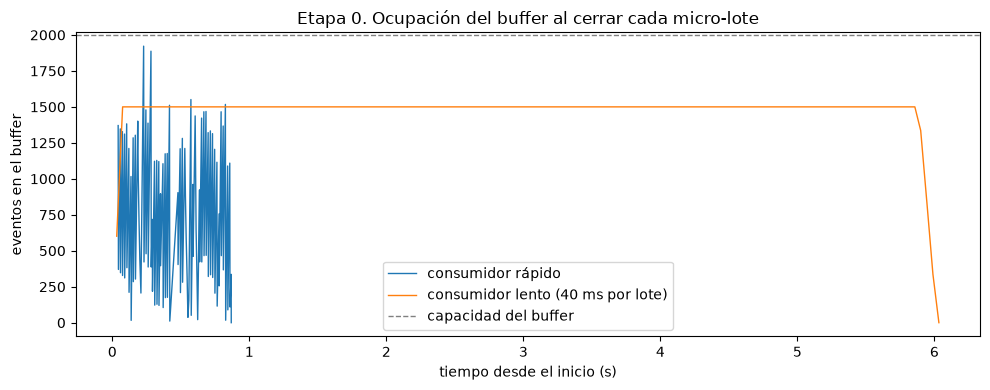

Ambos escenarios entregaron 71,836 eventos. El backpressure no perdió ninguno.


In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(lotes_rapido["t_s"], lotes_rapido["ocupacion_buffer"], label="consumidor rápido", lw=1)
ax.plot(lotes_lento["t_s"], lotes_lento["ocupacion_buffer"], label="consumidor lento (40 ms por lote)", lw=1)
ax.axhline(metricas_lento["capacidad"], color="gray", ls="--", lw=1, label="capacidad del buffer")
ax.set_xlabel("tiempo desde el inicio (s)")
ax.set_ylabel("eventos en el buffer")
ax.set_title("Etapa 0. Ocupación del buffer al cerrar cada micro-lote")
ax.legend()
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / f"etapa0_ocupacion_buffer_{CATEGORIA}.png", dpi=150)
plt.show()

# Los dos escenarios procesan exactamente los mismos eventos (misma semilla)
assert metricas_rapido["eventos"] == metricas_lento["eventos"]
print(f"Ambos escenarios entregaron {metricas_rapido['eventos']:,} eventos. El backpressure no perdió ninguno.")

### Micro-lotes cerrados por tiempo

En los dos escenarios anteriores todos los lotes se cerraron por tamaño, porque el generador produce más de 500 eventos cada 50 ms. Para comprobar el cierre por tiempo se simula un stream de poco tráfico. Un productor pone un evento cada 2 ms, es decir, unos 25 eventos en cada ventana de 50 ms. Como el lote nunca alcanza 500 eventos, cada lote debe cerrarse por tiempo, y ningún evento debe esperar más de unos 50 ms en el buffer. En Windows la pausa real de time.sleep es algo mayor que 2 ms, por lo que cada lote reúne unos 20 eventos y no 25.

In [14]:
buffer_lento = BufferConBackpressure(capacidad=2_000)

def productor_poco_trafico(n_eventos=500, pausa_s=0.002):
    for i in range(n_eventos):
        buffer_lento.poner({"event_id": i, "llegada": time.perf_counter()})
        time.sleep(pausa_s)
    buffer_lento.cerrar()

hilo = threading.Thread(target=productor_poco_trafico, daemon=True)
hilo.start()
filas = []
for lote, motivo in micro_lotes(buffer_lento, tam_lote=500, max_espera_s=0.05):
    salida = time.perf_counter()
    filas.append({"tamano": len(lote), "motivo": motivo,
                  "espera_max_ms": (salida - min(e["llegada"] for e in lote)) * 1000})
hilo.join()

lotes_poco_trafico = pd.DataFrame(filas)
print(lotes_poco_trafico["motivo"].value_counts().to_dict())
lotes_poco_trafico.describe().round(1)

{'tiempo': 23, 'fin': 1}


,tamano,espera_max_ms
count,24.0,24.0
mean,20.8,47.9
std,3.1,6.7
min,7.0,16.6
25%,21.0,48.3
50%,21.0,49.2
75%,22.0,50.0
max,23.0,51.2


## Paso 8. Experimentos de complejidad

### Diseño del experimento

Se compara el costo de usar cuatro estructuras como cola FIFO.

| Estructura | `encolar` | `desencolar` | Costo esperado de n + n operaciones |
| --- | --- | --- | --- |
| `list` con `append` y `pop(0)` | O(1) amortizado | O(n) | O(n²) |
| `collections.deque` (línea base) | O(1) | O(1) | O(n) |
| `ColaEnlazada` (propia) | O(1) | O(1) | O(n) |
| `ColaCircular` (propia) | O(1) | O(1) | O(n) |

Cada medición encola n elementos y luego los desencola todos. Las decisiones del experimento son las siguientes.

- **Tamaños.** 1K, 10K, 100K, 1M y 10M, como pide el enunciado.
- **Repeticiones.** 100 para 1K y 10K, 20 para 100K, 5 para 1M y 3 para 10M. Se reducen en los tamaños grandes porque cada repetición tarda varios segundos y la desviación estándar ya es pequeña frente a la media.
- **Límite de `list.pop(0)`.** Se mide solo hasta 100K, con 5 repeticiones en ese tamaño. Por su costo O(n²), a 1M tardaría del orden de horas.
- **Elemento encolado.** Siempre es el mismo objeto, para medir solo el costo de la estructura y no el de crear elementos.
- **Recolector de basura.** Se desactiva durante cada medición (`gc.disable`). Así sus pausas no se mezclan con el tiempo de la estructura.
- **Reloj.** `time.perf_counter`, el reloj de mayor resolución disponible en Python.

Los resultados se guardan en `results/etapa0_cola_tiempos.csv`. Si el archivo ya existe, el notebook lo lee en lugar de repetir las mediciones. Para medir de nuevo se cambia `REEJECUTAR_EXPERIMENTOS` a `True`.

In [15]:
REEJECUTAR_EXPERIMENTOS = False
TAMANOS = [1_000, 10_000, 100_000, 1_000_000, 10_000_000]
REPETICIONES = {1_000: 100, 10_000: 100, 100_000: 20, 1_000_000: 5, 10_000_000: 3}
LIMITE_LISTA = 100_000          # list.pop(0) es O(n²): no se mide por encima de este tamaño
ELEMENTO = object()             # el mismo objeto en todas las operaciones


# Cada fábrica recibe n y devuelve las funciones (encolar, desencolar) de una cola nueva
def fabrica_lista(n):
    cola = []
    return cola.append, partial(cola.pop, 0)

def fabrica_deque(n):
    cola = deque()
    return cola.append, cola.popleft

def fabrica_enlazada(n):
    cola = ColaEnlazada()
    return cola.encolar, cola.desencolar

def fabrica_circular(n):
    cola = ColaCircular(n)
    return cola.encolar, cola.desencolar

ESTRUCTURAS = {
    "list.pop(0)": fabrica_lista,
    "collections.deque": fabrica_deque,
    "ColaEnlazada (propia)": fabrica_enlazada,
    "ColaCircular (propia)": fabrica_circular,
}


def medir_tiempo(fabrica, n):
    """Tiempo en segundos de n operaciones encolar seguidas de n operaciones desencolar."""
    encolar, desencolar = fabrica(n)
    gc.collect()
    gc.disable()
    try:
        t0 = time.perf_counter()
        for _ in range(n):
            encolar(ELEMENTO)
        for _ in range(n):
            desencolar()
        return time.perf_counter() - t0
    finally:
        gc.enable()


def repeticiones_para(nombre, n):
    if nombre == "list.pop(0)" and n >= LIMITE_LISTA:
        return min(REPETICIONES[n], 5)
    return REPETICIONES[n]


ruta_tiempos = CARPETA_RESULTADOS / "etapa0_cola_tiempos.csv"
if ruta_tiempos.exists() and not REEJECUTAR_EXPERIMENTOS:
    tiempos = pd.read_csv(ruta_tiempos)
    print(f"Resultados leídos de {ruta_tiempos.relative_to(RAIZ)}")
else:
    filas = []
    for n in TAMANOS:
        for nombre, fabrica in ESTRUCTURAS.items():
            if nombre == "list.pop(0)" and n > LIMITE_LISTA:
                continue
            for rep in range(repeticiones_para(nombre, n)):
                filas.append({"estructura": nombre, "n": n, "repeticion": rep,
                              "segundos": medir_tiempo(fabrica, n)})
        print(f"n = {n:>10,} medido")
    tiempos = pd.DataFrame(filas)
    tiempos.to_csv(ruta_tiempos, index=False)
    print(f"Resultados guardados en {ruta_tiempos.relative_to(RAIZ)}")

resumen = (tiempos.groupby(["estructura", "n"])["segundos"]
           .agg(promedio_s="mean", desv_est_s="std", repeticiones="count").reset_index())
resumen["ns_por_operacion"] = resumen["promedio_s"] / (2 * resumen["n"]) * 1e9
resumen

Resultados leídos de results\etapa0_cola_tiempos.csv


,estructura,n,promedio_s,desv_est_s,repeticiones,ns_por_operacion
0,ColaCircular (propia),1000,0.000461,0.000047,100,230.386500
1,ColaCircular (propia),10000,0.005209,0.000503,100,260.436200
2,ColaCircular (propia),100000,0.039854,0.000625,20,199.269200
3,ColaCircular (propia),1000000,0.393899,0.012907,5,196.949720
4,ColaCircular (propia),10000000,3.769137,0.038300,3,188.456825
5,ColaEnlazada (propia),1000,0.000547,0.000283,100,273.607500
6,ColaEnlazada (propia),10000,0.004990,0.000768,100,249.478550
7,ColaEnlazada (propia),100000,0.041346,0.001338,20,206.729425
8,ColaEnlazada (propia),1000000,0.408136,0.006215,5,204.067760
9,ColaEnlazada (propia),10000000,4.464754,0.380783,3,223.237718


### Escalabilidad en escala log-log

En una gráfica log-log, un costo de la forma T(n) = c·nᵏ aparece como una recta de pendiente k. Una estructura O(n) debe mostrar pendiente cercana a 1 y una O(n²) pendiente cercana a 2. Las líneas punteadas son las referencias teóricas, ancladas en el primer punto de `ColaCircular` y de `list.pop(0)`.

La gráfica de la derecha muestra el tiempo por operación. Si cada operación es O(1), esa curva se mantiene casi plana al crecer n.

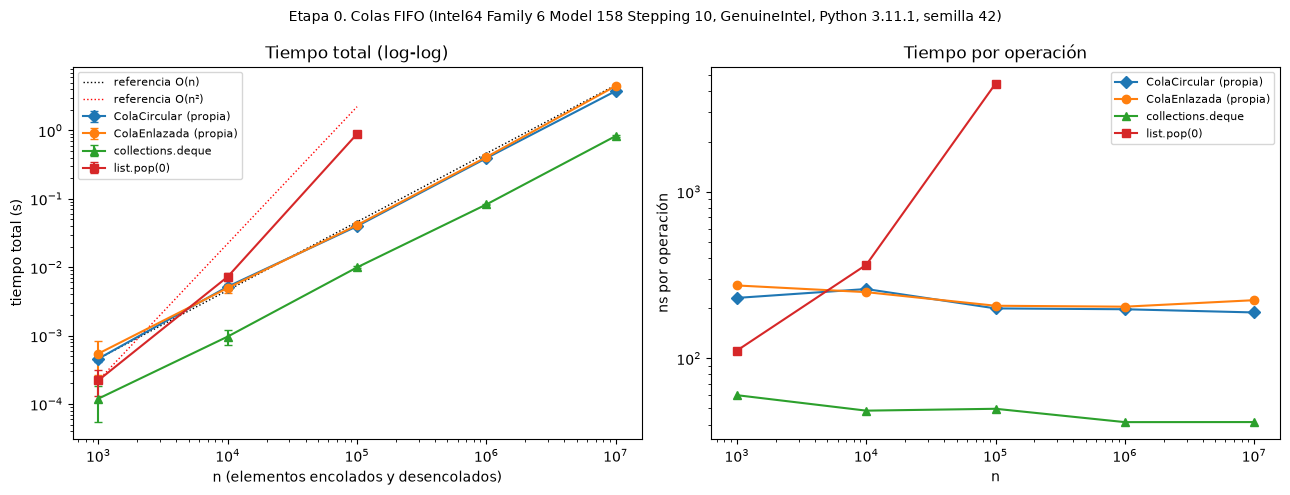

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
marcadores = {"list.pop(0)": "s", "collections.deque": "^",
              "ColaEnlazada (propia)": "o", "ColaCircular (propia)": "D"}

for nombre, datos in resumen.groupby("estructura"):
    ax1.errorbar(datos["n"], datos["promedio_s"], yerr=datos["desv_est_s"],
                 marker=marcadores[nombre], capsize=3, label=nombre)
    ax2.plot(datos["n"], datos["ns_por_operacion"], marker=marcadores[nombre], label=nombre)

# Referencias teóricas
n_ref = np.array(TAMANOS, dtype=float)
base_circ = resumen.query("estructura == 'ColaCircular (propia)'").iloc[0]
base_lista = resumen.query("estructura == 'list.pop(0)'").iloc[0]
ax1.plot(n_ref, base_circ["promedio_s"] * n_ref / base_circ["n"], "k:", lw=1, label="referencia O(n)")
n_lista = n_ref[n_ref <= LIMITE_LISTA]
ax1.plot(n_lista, base_lista["promedio_s"] * (n_lista / base_lista["n"]) ** 2, "r:", lw=1,
         label="referencia O(n²)")

ax1.set_xscale("log"); ax1.set_yscale("log")
ax1.set_xlabel("n (elementos encolados y desencolados)"); ax1.set_ylabel("tiempo total (s)")
ax1.set_title("Tiempo total (log-log)")
ax1.legend(fontsize=8)

ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel("n"); ax2.set_ylabel("ns por operación")
ax2.set_title("Tiempo por operación")
ax2.legend(fontsize=8)

plt.suptitle(f"Etapa 0. Colas FIFO ({PLATAFORMA['procesador']}, Python {PLATAFORMA['python']}, semilla {SEED})",
             fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa0_escalabilidad.png", dpi=150)
plt.show()

### Pendiente empírica

Se ajusta una recta a log(tiempo) frente a log(n) con mínimos cuadrados (`np.polyfit`). La pendiente estimada se compara con el exponente teórico.

In [17]:
TEORICO = {"list.pop(0)": 2, "collections.deque": 1, "ColaEnlazada (propia)": 1, "ColaCircular (propia)": 1}

pendientes = []
for nombre, datos in resumen.groupby("estructura"):
    k, _ = np.polyfit(np.log10(datos["n"]), np.log10(datos["promedio_s"]), 1)
    pendientes.append({"estructura": nombre, "pendiente_empirica": round(k, 2),
                       "exponente_teorico": TEORICO[nombre],
                       "rango_n": f"{datos['n'].min():,} a {datos['n'].max():,}"})
pd.DataFrame(pendientes)

,estructura,pendiente_empirica,exponente_teorico,rango_n
0,ColaCircular (propia),0.97,1,"1,000 a 10,000,000"
1,ColaEnlazada (propia),0.97,1,"1,000 a 10,000,000"
2,collections.deque,0.96,1,"1,000 a 10,000,000"
3,list.pop(0),1.80,2,"1,000 a 100,000"


### Memoria actual y pico

Se mide con `tracemalloc` la memoria que ocupa cada cola después de encolar n elementos (memoria actual) y la memoria máxima alcanzada durante todo el proceso (memoria pico). Como el elemento encolado es siempre el mismo objeto, la cifra corresponde solo a la estructura. La memoria se mide hasta 1M porque `tracemalloc` registra cada asignación y a 10M multiplica el tiempo y la memoria de la medición. Al ser O(n), el valor a 10M se puede extrapolar multiplicando por 10.

Se espera que `ColaCircular` use unos 8 bytes por elemento (una referencia en el arreglo) y que `ColaEnlazada` use bastante más, porque cada nodo es un objeto completo.

In [18]:
def medir_memoria(fabrica, n):
    """Devuelve (memoria con n elementos encolados, memoria pico) en bytes."""
    gc.collect()
    tracemalloc.start()
    encolar, desencolar = fabrica(n)
    for _ in range(n):
        encolar(ELEMENTO)
    actual, _ = tracemalloc.get_traced_memory()
    for _ in range(n):
        desencolar()
    _, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return actual, pico


ruta_memoria = CARPETA_RESULTADOS / "etapa0_cola_memoria.csv"
if ruta_memoria.exists() and not REEJECUTAR_EXPERIMENTOS:
    memoria = pd.read_csv(ruta_memoria)
else:
    filas = []
    for n in [1_000, 10_000, 100_000, 1_000_000]:
        for nombre, fabrica in ESTRUCTURAS.items():
            if nombre == "list.pop(0)" and n > LIMITE_LISTA:
                continue
            actual, pico = medir_memoria(fabrica, n)
            filas.append({"estructura": nombre, "n": n, "actual_mb": actual / 1e6, "pico_mb": pico / 1e6})
    memoria = pd.DataFrame(filas)
    memoria.to_csv(ruta_memoria, index=False)

memoria["bytes_por_elemento"] = memoria["pico_mb"] * 1e6 / memoria["n"]
memoria.pivot(index="n", columns="estructura", values="bytes_por_elemento").round(1)

estructura,ColaCircular (propia),ColaEnlazada (propia),collections.deque,list.pop(0)
n,,,,
1000,8.7,48.5,9.6,9.4
10000,8.1,48.1,8.4,8.6
100000,8.0,48.0,8.3,8.0
1000000,8.0,48.0,8.3,NaN


### Lectura de los resultados

Los valores citados corresponden a la ejecución guardada en `results/`. Al medir de nuevo pueden variar ligeramente.

- `ColaCircular`, `ColaEnlazada` y `deque` muestran pendientes cercanas a 1 (entre 0.96 y 0.97) y un tiempo por operación casi constante entre 1K y 10M. Esto confirma el costo O(1) por operación y O(n) en total.
- `list.pop(0)` muestra un tiempo por operación que crece con n, de unos 110 ns a 1K hasta unos 4 400 ns a 100K. Su pendiente global es 1.8 y no 2 porque a 1K el costo fijo del bucle de Python domina sobre el desplazamiento de elementos. Entre 10K y 100K, donde domina el desplazamiento, el tiempo crece unas 120 veces cuando n crece 10 veces, lo que corresponde a una pendiente cercana a 2.
- `deque` es unas 4 a 5 veces más rápida que las colas propias porque está implementada en C, mientras que las propias se ejecutan como código Python interpretado. La diferencia es un factor constante y no cambia el orden de complejidad.
- En memoria, `ColaCircular` usa 8 bytes por elemento, igual que `deque` y `list`, porque solo guarda una referencia por posición. `ColaEnlazada` usa unos 48 bytes por elemento, seis veces más, porque cada nodo es un objeto de Python.

Por estas razones, el buffer de la etapa 0 usa `ColaCircular`. Su costo es O(1) por operación, su memoria es fija y conocida, y su capacidad acotada permite aplicar backpressure. `ColaEnlazada` se reserva para colas sin límite, como la cola de rechazados de la etapa 1.

## Paso 9. Salida de la etapa 0 para la etapa 1

La etapa 0 entrega micro-lotes de registros crudos. Mientras cada etapa esté en su propio notebook, la salida se guarda en archivos dentro de `data/interim/<CATEGORIA>/`, que no se versiona. Las etapas 1 y 2 toman la misma carpeta de `src/config.py`. El notebook de la etapa 1 los leerá lote por lote.

| Archivo | Contenido | Lo usa |
| --- | --- | --- |
| `etapa0_lotes.jsonl` | Una línea por micro-lote con su número y sus registros crudos | Etapa 1 |
| `etapa0_inyecciones.json` | Conteos de duplicados, malformados y tardíos inyectados (verdad de referencia) | Etapa 1, para medir la deduplicación y la validación |
| `listas_senalados.json` | Cuentas, tarjetas y dispositivos señalados | Etapa 6 (Bloom Filter) |

Se procesan las reseñas que indica `config.MODO`: 50 000 en desarrollo y 2 500 000 en el experimento. La función `guardar_lote` cumple el papel de la etapa 1 dentro de `ejecutar_etapa0`, lo que muestra cómo se conectarán las etapas.

In [19]:
N_RESENAS_SALIDA = config.n_resenas()
ruta_lotes = CARPETA_INTERIM / "etapa0_lotes.jsonl"

with open(ruta_lotes, "w", encoding="utf-8") as archivo_lotes:
    def guardar_lote(numero, lote):
        archivo_lotes.write(json.dumps({"lote": numero, "registros": lote}) + "\n")

    metricas_salida, lotes_salida, generador_salida = ejecutar_etapa0(
        N_RESENAS_SALIDA, al_recibir_lote=guardar_lote)

inyecciones = dict(generador_salida.estadisticas)
inyecciones.update(categoria=CATEGORIA, modo=config.MODO, n_resenas=N_RESENAS_SALIDA, semilla=SEED,
                   porcentaje_tardios=config.PORCENTAJE_TARDIOS,
                   retraso_max_tardios_s=config.RETRASO_MAX_TARDIOS_S)
(CARPETA_INTERIM / "etapa0_inyecciones.json").write_text(json.dumps(inyecciones, indent=2), encoding="utf-8")
(CARPETA_INTERIM / "listas_senalados.json").write_text(
    json.dumps(generador_salida.listas_senalados(), indent=2), encoding="utf-8")

print(f"Archivo de lotes: {ruta_lotes.relative_to(RAIZ)}  ({ruta_lotes.stat().st_size / 1e6:.1f} MB)")
pd.Series(metricas_salida, name="valor").to_frame()

Archivo de lotes: data\interim\Office_Products\etapa0_lotes.jsonl  (114.7 MB)


,valor
eventos,363511.00
lotes,728.00
lotes_por_tamano,727.00
lotes_por_tiempo,0.00
duracion_s,5.39
eventos_por_s,67454.00
bloqueos_productor,680.00
espera_productor_s,1.64
ocupacion_maxima,2000.00
capacidad,2000.00


### Verificación de la salida

Se vuelve a leer el archivo para confirmar que el número de eventos guardados coincide con el número de eventos emitidos por el generador.

In [20]:
total_guardado = 0
with open(ruta_lotes, encoding="utf-8") as f:
    for linea in f:
        total_guardado += len(json.loads(linea)["registros"])

assert total_guardado == inyecciones["emitidos"] == metricas_salida["eventos"]
print(f"Eventos emitidos por el generador: {inyecciones['emitidos']:,}")
print(f"Eventos guardados en {metricas_salida['lotes']} lotes: {total_guardado:,}")
print("La etapa 0 entregó todos los eventos, sin pérdidas.")

Eventos emitidos por el generador: 363,511
Eventos guardados en 728 lotes: 363,511
La etapa 0 entregó todos los eventos, sin pérdidas.


## Resumen de la etapa 0

| Aspecto | Decisión |
| --- | --- |
| Lectura del dataset | Parquet leído por bloques con `iter_batches` dentro de una ventana reciente; memoria O(1) respecto al número de reseñas |
| Desorden | Controlado: 5 % de eventos tardíos con un retraso de hasta `RETRASO_MAX_TARDIOS_S`; sin tardíos el stream sale ordenado |
| Estructura del buffer | `ColaCircular` propia, capacidad fija, `encolar` y `desencolar` en O(1) |
| Estructura alternativa | `ColaEnlazada` propia, sin límite, para la cola de rechazados de la etapa 1 |
| Concurrencia | Productor en un hilo, consumidor en el hilo principal, sincronizados con `Lock` y `Condition` |
| Backpressure | El productor se bloquea si el buffer está lleno; no se pierden eventos y la memoria queda acotada |
| Micro-lotes | Se cierran al llegar a 500 eventos o al pasar 50 ms, lo que ocurra primero |
| Salida | Micro-lotes de registros crudos en `data/interim/<CATEGORIA>/etapa0_lotes.jsonl` |

Referencias. Cormen, T. H., Leiserson, C. E., Rivest, R. L., y Stein, C. (2022). *Introduction to Algorithms* (4.ª ed.), cap. 10. Leskovec, J., Rajaraman, A., y Ullman, J. D. (2020). *Mining of Massive Datasets* (3.ª ed.), cap. 4.